In [2]:
from typing import Iterable
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, rv_continuous, mannwhitneyu
from scipy.special import erfc, erf
from astropy.convolution import convolve, Gaussian1DKernel

In [3]:
PDF_X = np.linspace(0, 200, 10000)
trapezoid = np.trapz

In [4]:
class AsymmetricGaussian(rv_continuous):
    """
    Custom Asymmetric Gaussian distribution.
    Use loc for the mean, and unc_minus/unc_plus as shape parameters.
    """

    def _pdf(self, x, mean, unc_minus, unc_plus):
        """x is already shifted by loc internally by scipy, so we don't need to pass
        the mean"""
        pdf = np.where(
            x < mean,
            np.exp(-0.5 * ((x-mean) / unc_minus) ** 2),
            np.exp(-0.5 * ((x-mean) / unc_plus) ** 2),
        )

        norm = np.sqrt(2 / np.pi) * (unc_plus + unc_minus*erf(mean/(unc_minus*np.sqrt(2))))**-1
        return norm * pdf

ag = AsymmetricGaussian()

In [5]:
def normalization_prefactor(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos):
    prefactor_cand = np.sqrt(2/np.pi) * (sigma_cand_pos + sigma_cand_neg*erf(mean_cand/(sigma_cand_neg*np.sqrt(2))))**-1
    prefactor_gw = float(sigma_gw)**-1 * np.sqrt(2/np.pi) * (1 + erf(mean_gw/(sigma_gw*np.sqrt(2))))**-1
    return np.sqrt(prefactor_cand*prefactor_gw)

def a(sigma_gw, sigma_cand):
    return 1/sigma_gw**2 + 1/sigma_cand**2

def b(mean_gw, sigma_gw, mean_cand, sigma_cand):
    return mean_gw/sigma_gw**2 + mean_cand/sigma_cand**2

def c(mean_gw, sigma_gw, mean_cand, sigma_cand):
    return (mean_gw/sigma_gw)**2 + (mean_cand/sigma_cand)**2

def p(_a, _b, _c):
    return np.sqrt(np.pi/_a) * np.exp(-0.25*(_c - _b**2/_a))

def bc_integral_neg(mean_gw, sigma_gw, mean_cand, sigma_cand_neg):
    _a = a(sigma_gw, sigma_cand_neg)
    _b = b(mean_gw, sigma_gw, mean_cand, sigma_cand_neg)
    _c = c(mean_gw, sigma_gw, mean_cand, sigma_cand_neg)

    _p = p(_a, _b, _c)
    x0 = erf(-_b/(2*np.sqrt(_a)))
    x1 = erf(np.sqrt(_a)/2 * (mean_cand - _b/_a))
    # print("neg", _p*(x1-x0))
    return _p*(x1-x0)

def bc_integral_pos(mean_gw, sigma_gw, mean_cand, sigma_cand_pos):
    _a = a(sigma_gw, sigma_cand_pos)
    _b = b(mean_gw, sigma_gw, mean_cand, sigma_cand_pos)
    _c = c(mean_gw, sigma_gw, mean_cand, sigma_cand_pos)

    _p = p(_a, _b, _c)
    # print("pos", _p*erfc(np.sqrt(_a)/2 * (mean_cand - _b/_a)))
    return _p*erfc(np.sqrt(_a)/2 * (mean_cand - _b/_a))

def bc(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos):
    lower_args = (mean_gw, sigma_gw, mean_cand, sigma_cand_neg)
    upper_args = (mean_gw, sigma_gw, mean_cand, sigma_cand_pos)
    norm = normalization_prefactor(mean_gw, sigma_gw, mean_cand, sigma_cand_neg, sigma_cand_pos)
    # print(norm, bc_integral_neg(*lower_args), bc_integral_pos(*upper_args))
    return norm*(bc_integral_neg(*lower_args) + bc_integral_pos(*upper_args))

def sigmoid(x, k=1):
    return 1 / (1 + np.exp(-k * x))

def smooth_tophat(x, a, b, k=1):
    return sigmoid(x - a, k) * (1 - sigmoid(x - b, k))

def smooth_tophat_score(galaxy_dist, gw_mean, gw_std, nsigma=2):
    return smooth_tophat(galaxy_dist, gw_mean-nsigma*gw_std, gw_mean+nsigma*gw_std)


def hybrid(mean1, mean2, std1, unc_minus, unc_plus):

    bc_score = bc(mean1, std1, mean2, unc_minus, unc_plus)
    tophat_score = smooth_tophat_score(mean1, mean2, std1)

    # this weight will be small for spec-z's and large for photo-z's   
    w = np.mean([unc_minus, unc_plus], axis=0) / std1
    max_w = np.ones(w.shape)
    w = np.min([max_w, w], axis=0)

    return (1-w)*tophat_score + w*bc_score

In [8]:
base_pdf = norm.pdf(PDF_X, loc=100, scale=5)
# test_pdfs = dict(
#     base_pdf = dict(mean=100,unc_minus=5, unc_plus=5, specz=False),
#     deltafunc_pdf = dict(mean=100, unc_minus=1, unc_plus=1, specz=True),
#     deltafunc_slightly_offset_pdf = dict(mean=105, unc_minus=1, unc_plus=1, specz=True),
#     deltafunc_offset_pdf = dict(mean=150, unc_minus=1, unc_plus=1, specz=True),
#     wide_pdf = dict(mean=100,unc_minus=10, unc_plus=10, specz=False),
#     wide_pdf_offset = dict(mean=115, unc_minus=10, unc_plus=10, specz=False),
#     wide_pdf_veryoffset = dict(mean=150,unc_minus=10, unc_plus=10, specz=False),
#     verywide_pdf = dict(mean=100,unc_minus=50, unc_plus=50, specz=False),
#     verywide_slightly_offset_pdf = dict(mean=105,unc_minus=50, unc_plus=50, specz=False),
#     verywide_pdf_offset = dict(mean=150,unc_minus=50, unc_plus=50, specz=False),
#     asymmetric_pdf_deltafunc = dict(mean=100, unc_minus=0.5, unc_plus=1, specz=False),
#     asymmetric_pdf_deltafunc_offset = dict(mean=150, unc_minus=0.5, unc_plus=1, specz=False),
#     asymmetric_pdf_wide = dict(mean=100, unc_minus=7.5, unc_plus=12.5, specz=False),
#     asymmetric_pdf_wide_offset = dict(mean=150, unc_minus=7.5, unc_plus=12.5, specz=False),
#     asymmetric_pdf_wide_offset_neg = dict(mean=50, unc_minus=7.5, unc_plus=12.5, specz=False),
#     asymmetric_pdf_very_skewed = dict(mean=100, unc_minus=50, unc_plus=1, specz=False),
#     asymmetric_pdf_very_skewed_offset = dict(mean=120, unc_minus=50, unc_plus=1, specz=False),
#     asymmetric_pdf_very_skewed_very_offset_pos = dict(mean=180, unc_minus=50, unc_plus=1, specz=False),
#     asymmetric_pdf_very_skewed_very_offset_neg = dict(mean=20, unc_minus=50, unc_plus=1, specz=False),
#     superdeltafunc_pdf = dict(mean = 100, unc_minus=1e-2, unc_plus=1e-2, specz=True),
#     superdeltafunc_pdf_slightlyoffset = dict(mean = 105, unc_minus=1e-2, unc_plus=1e-2, specz=True),
#     superdeltafunc_pdf_offset = dict(mean = 150, unc_minus=1e-2, unc_plus=1e-2, specz=True),
# )

test_pdfs = dict(
    base_pdf = dict(mean=100,unc_minus=5, unc_plus=5),
    deltafunc_pdf = dict(mean=100, unc_minus=1, unc_plus=1),
    deltafunc_slightly_offset_pdf = dict(mean=105, unc_minus=1, unc_plus=1),
    deltafunc_offset_pdf = dict(mean=150, unc_minus=1, unc_plus=1),
    wide_pdf = dict(mean=100,unc_minus=10, unc_plus=10),
    wide_slightly_offset_pdf = dict(mean=105, unc_minus=10, unc_plus=10),
    wide_pdf_offset = dict(mean=115, unc_minus=10, unc_plus=10),
    wide_pdf_veryoffset = dict(mean=150,unc_minus=10, unc_plus=10),
    verywide_pdf = dict(mean=100,unc_minus=50, unc_plus=50),
    verywide_slightly_offset_pdf = dict(mean=105,unc_minus=50, unc_plus=50),
    verywide_pdf_offset = dict(mean=150,unc_minus=50, unc_plus=50),
    asymmetric_pdf_deltafunc = dict(mean=100, unc_minus=0.5, unc_plus=1),
    asymmetric_pdf_deltafunc_offset = dict(mean=150, unc_minus=0.5, unc_plus=1),
    asymmetric_pdf_wide = dict(mean=100, unc_minus=7.5, unc_plus=12.5),
    asymmetric_pdf_wide_offset = dict(mean=150, unc_minus=7.5, unc_plus=12.5),
    asymmetric_pdf_wide_offset_neg = dict(mean=50, unc_minus=7.5, unc_plus=12.5),
    asymmetric_pdf_very_skewed = dict(mean=100, unc_minus=50, unc_plus=1),
    asymmetric_pdf_very_skewed_offset = dict(mean=120, unc_minus=50, unc_plus=1),
    asymmetric_pdf_very_skewed_very_offset_pos = dict(mean=180, unc_minus=50, unc_plus=1),
    asymmetric_pdf_very_skewed_very_offset_neg = dict(mean=20, unc_minus=50, unc_plus=1),
    asymmetric_pdf_very_skewed_slightly_offset_neg = dict(mean=95, unc_minus=50, unc_plus=1),
    asymmetric_pdf_very_skewed_moderately_offset_neg = dict(mean=92, unc_minus=50, unc_plus=1),
    # Straddles the GW: mode below (-6) with a narrow lower tail (unc_minus=1)
    # facing the GW and a wide upper tail (unc_plus=15) pointing away. The median
    # lands just above the GW, so v4 scores it on the narrow facing tail ALONE
    # and ignores the large far-side uncertainty; v2 blends both tails in. This
    # is the structure that maximizes the v2-vs-v4 disagreement.
    asymmetric_v4_straddle = dict(mean=94, unc_minus=1, unc_plus=15),
)

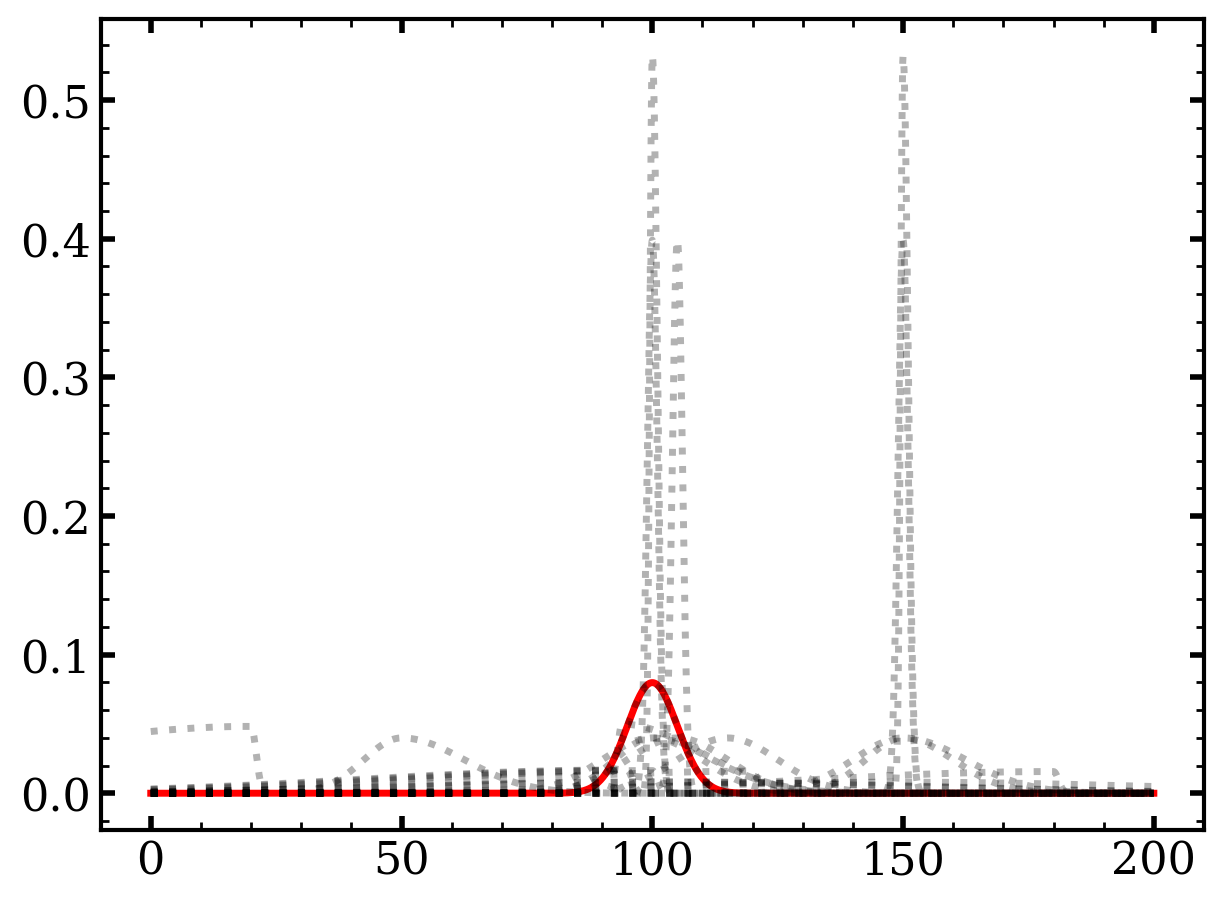

In [9]:
fig, ax = plt.subplots()

ax.plot(PDF_X, base_pdf, color="r")

for label, test_params in test_pdfs.items():
    # test_params.pop("specz")
    test = ag.pdf(PDF_X, **test_params)
    ax.plot(PDF_X, test, color="k", alpha=0.3, linestyle=":")

base_pdf 1.0000000000000002
deltafunc_pdf 0.9239620996480579
deltafunc_slightly_offset_pdf 0.8921771347533496
deltafunc_offset_pdf 4.5058055919178465e-12
wide_pdf 0.894427190999916
wide_slightly_offset_pdf 0.8508054621526306
wide_pdf_offset 0.5703119565575377
wide_pdf_veryoffset 0.006026603007498328
verywide_pdf 0.4501440362040477
verywide_slightly_offset_pdf 0.44791293302122903
verywide_pdf_offset 0.3476554175766578
asymmetric_pdf_deltafunc 0.9308816566597135
asymmetric_pdf_deltafunc_offset 1.05892529558726e-12
asymmetric_pdf_wide 0.8802634926115442
asymmetric_pdf_wide_offset 0.0003796844357957056
asymmetric_pdf_wide_offset_neg 0.029525946358597042
asymmetric_pdf_very_skewed 0.3815722690155921
asymmetric_pdf_very_skewed_offset 0.6030835316967276
asymmetric_pdf_very_skewed_very_offset_pos 0.33070478222030075
asymmetric_pdf_very_skewed_very_offset_neg 4.0005972469008128e-28
asymmetric_pdf_very_skewed_slightly_offset_neg 0.20928994670876988


/tmp/ipykernel_120706/4180071216.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


asymmetric_pdf_very_skewed_moderately_offset_neg 0.12364247879510641
asymmetric_v4_straddle 0.8751732016233555


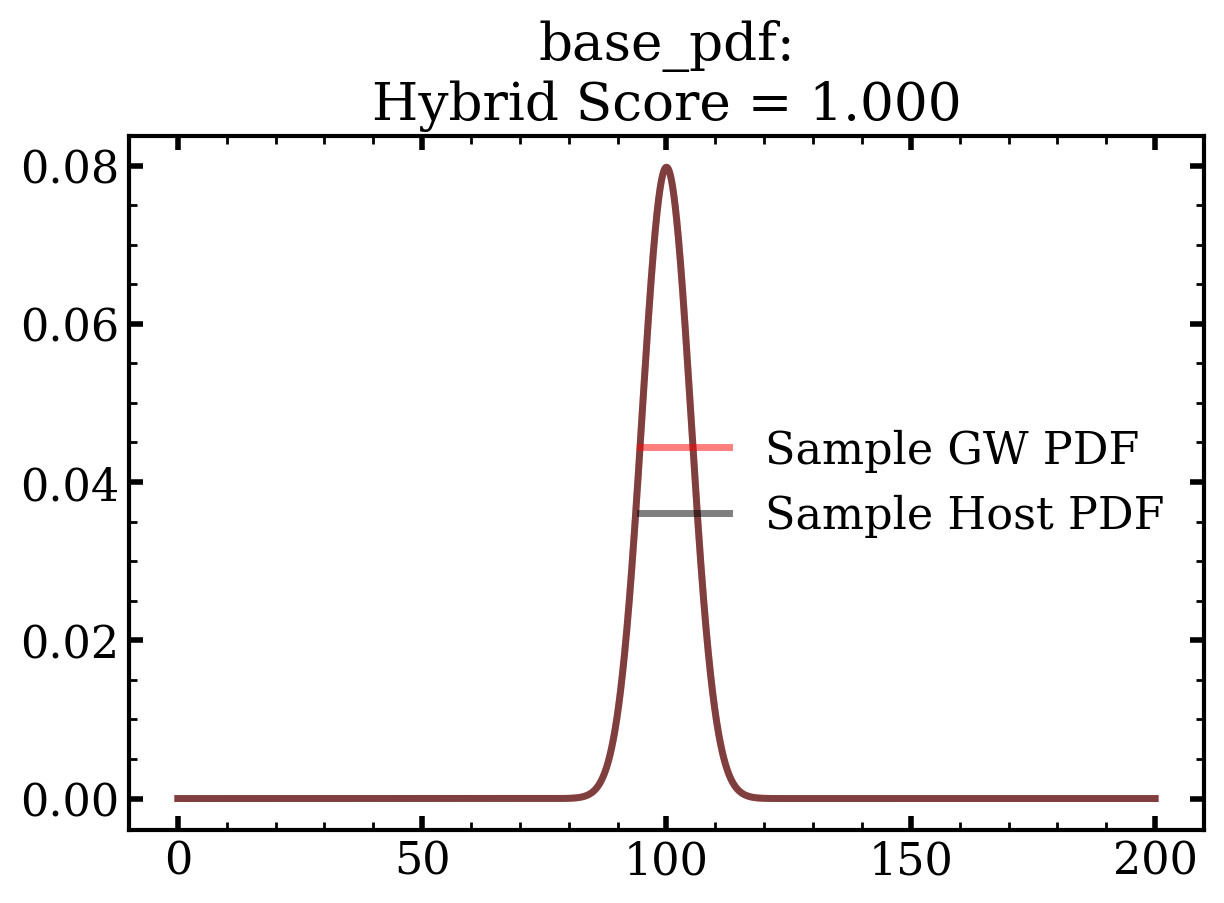

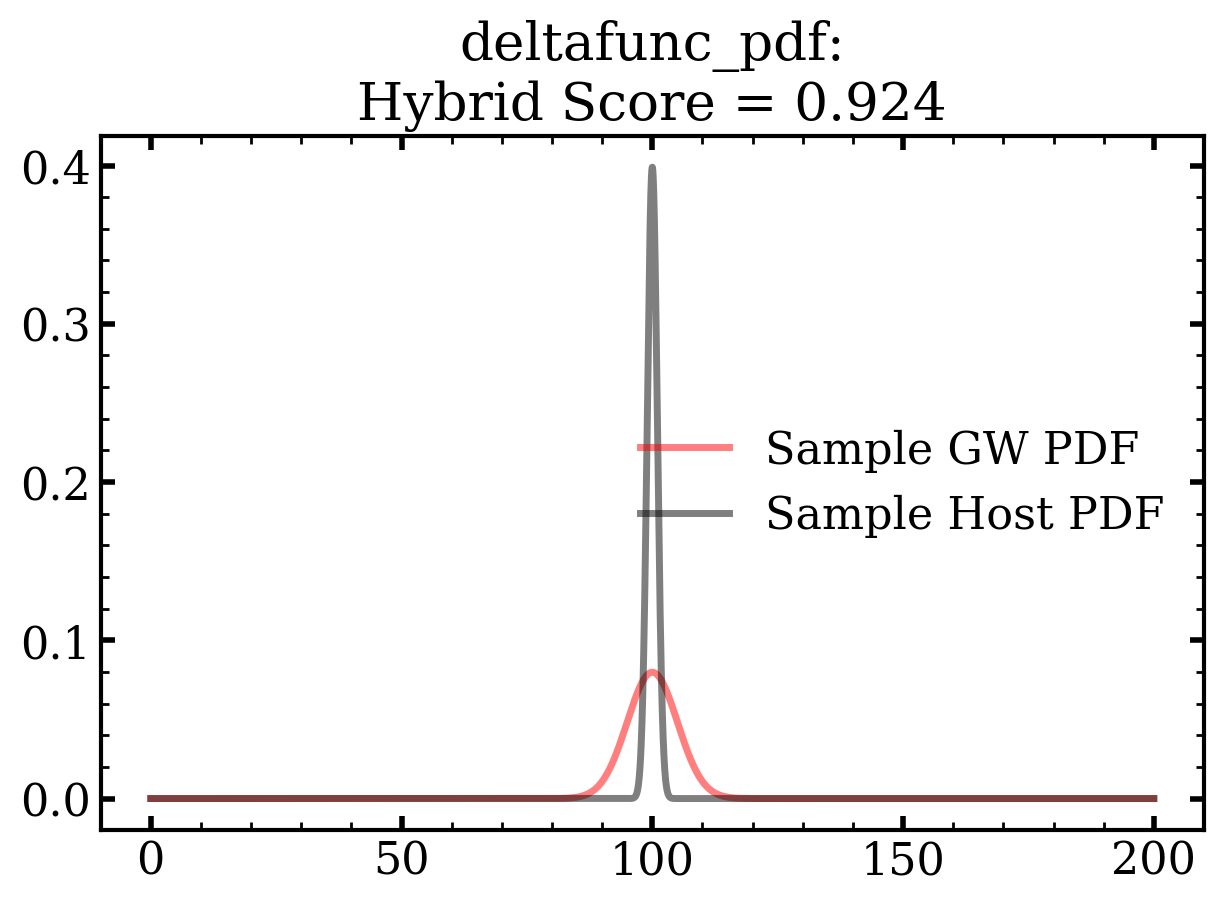

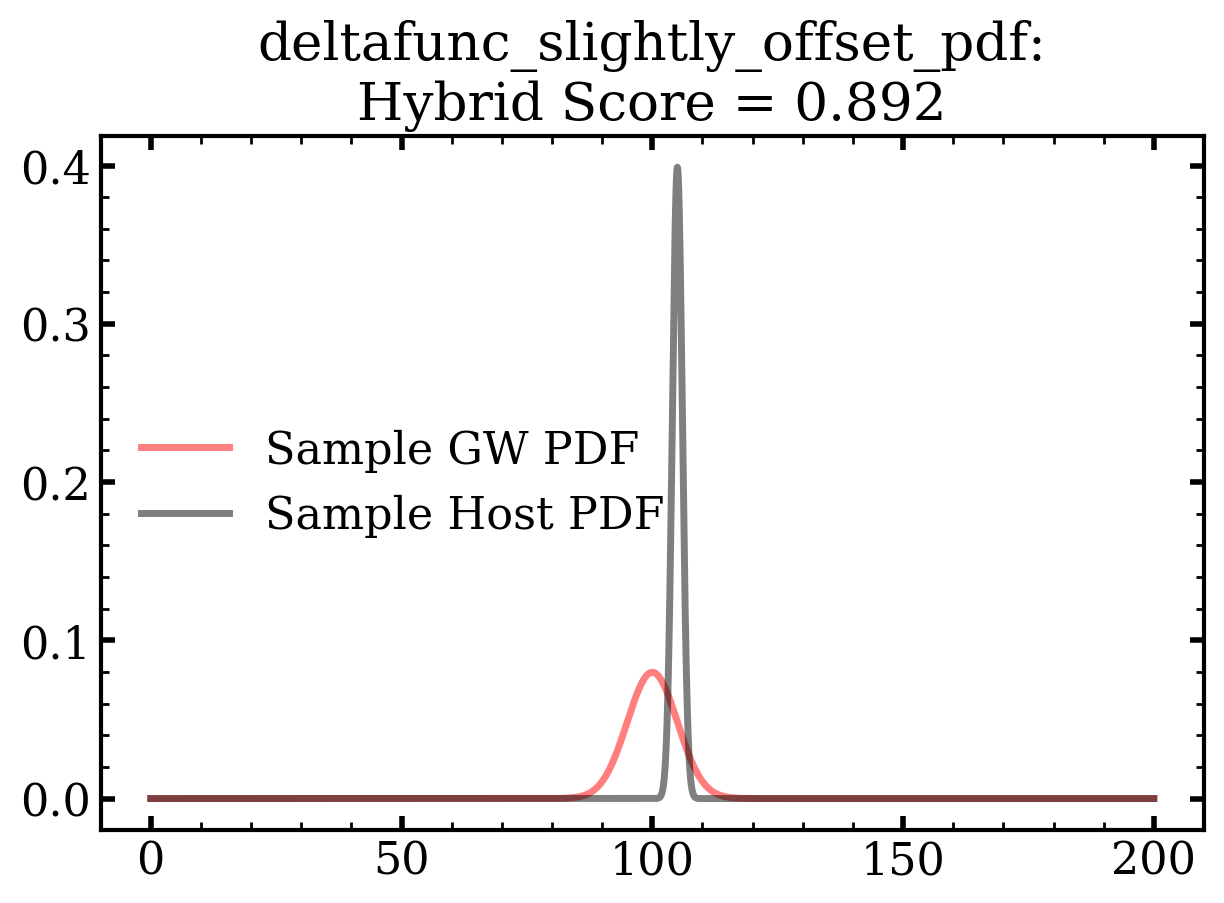

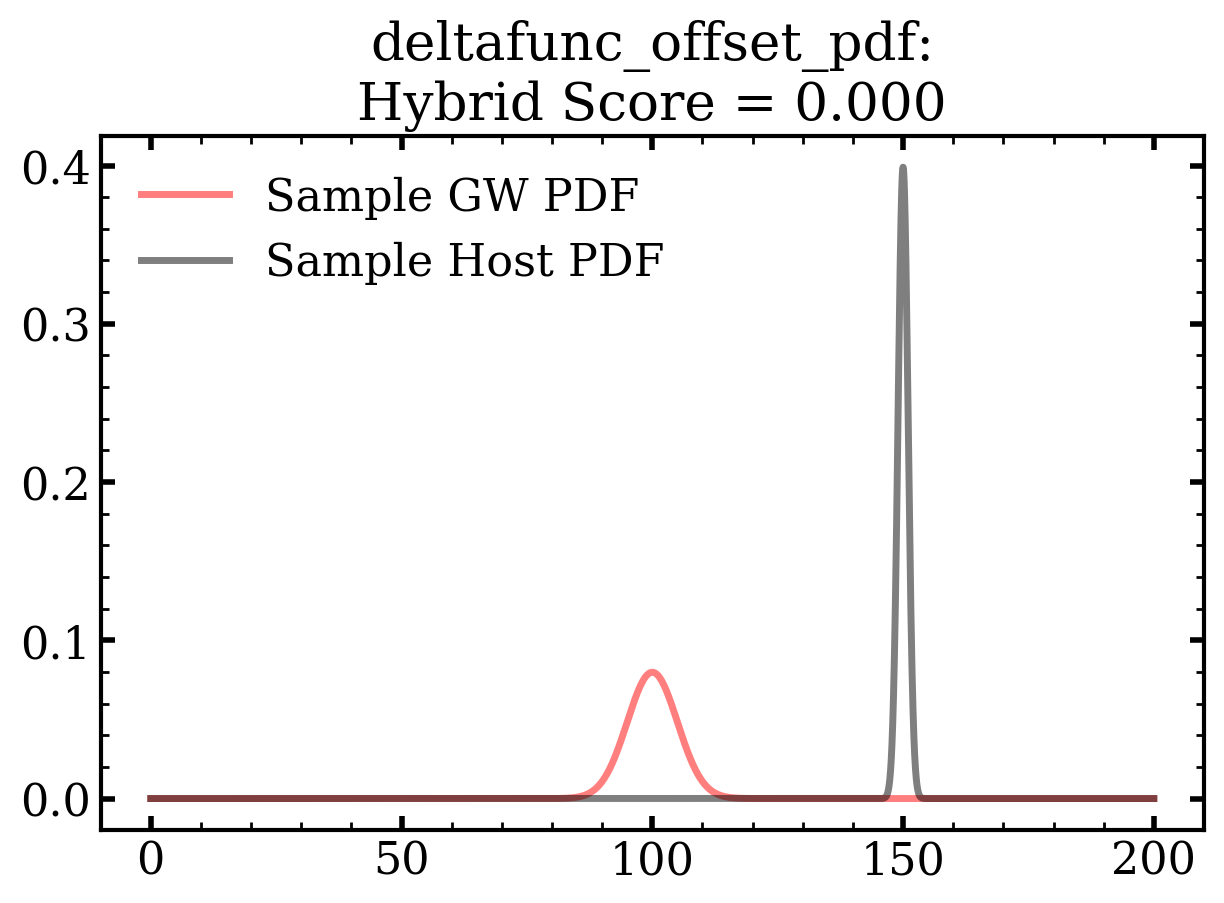

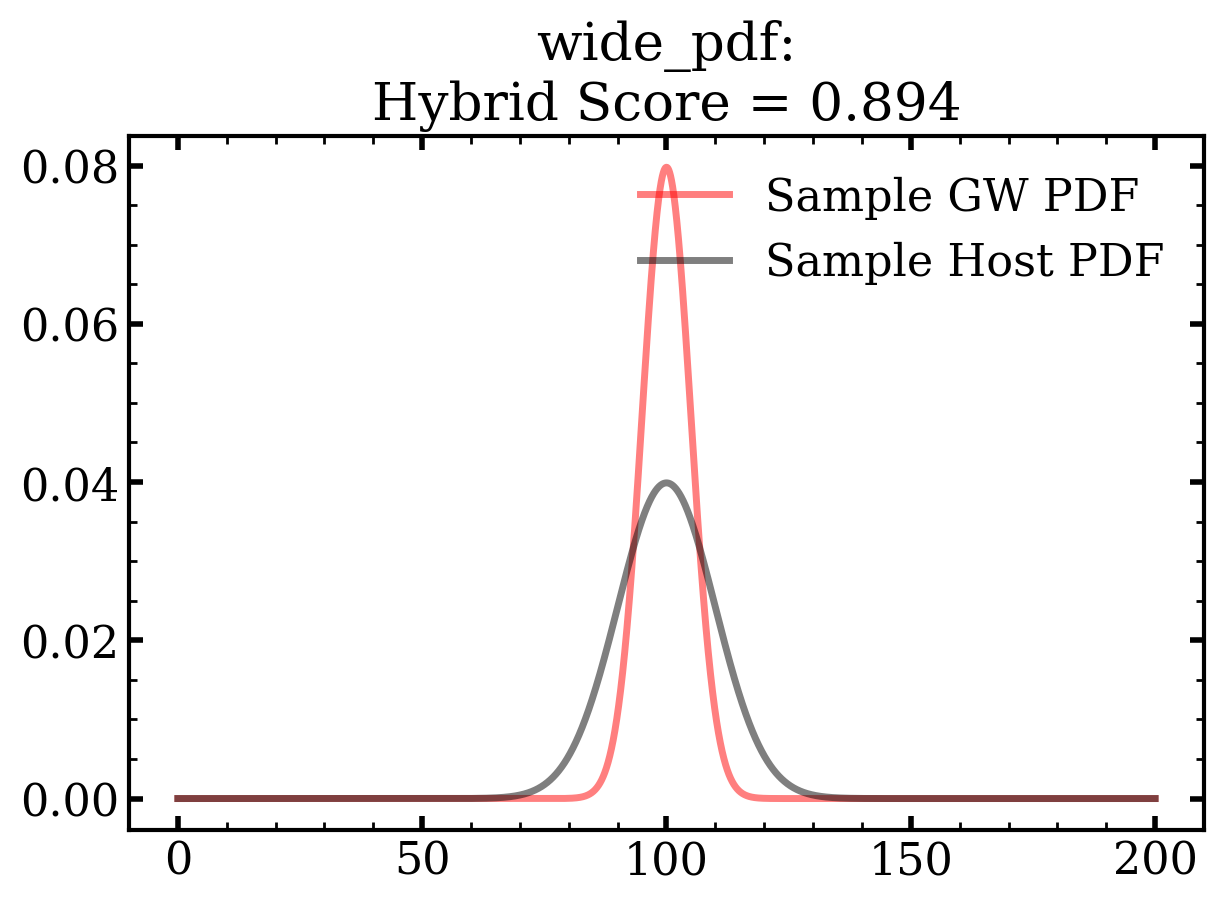

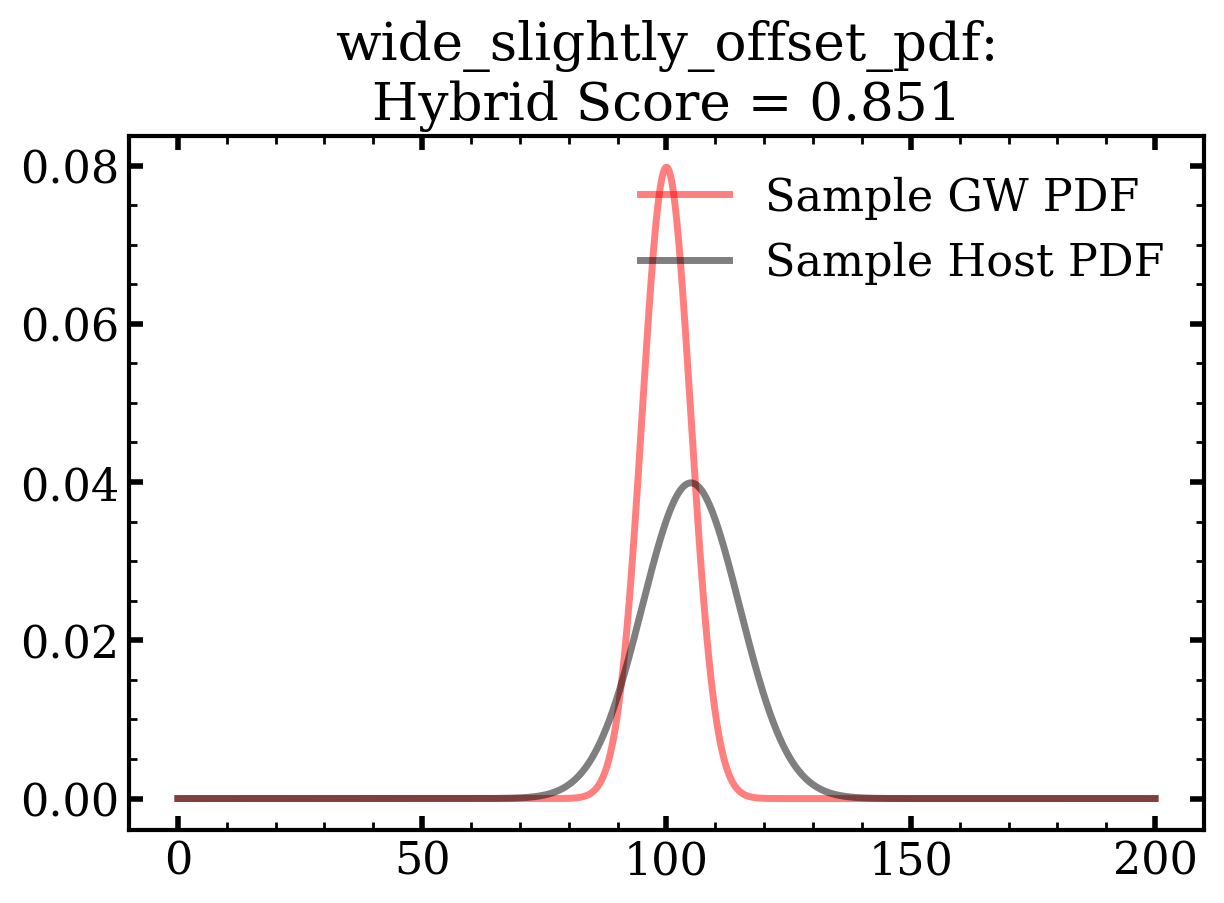

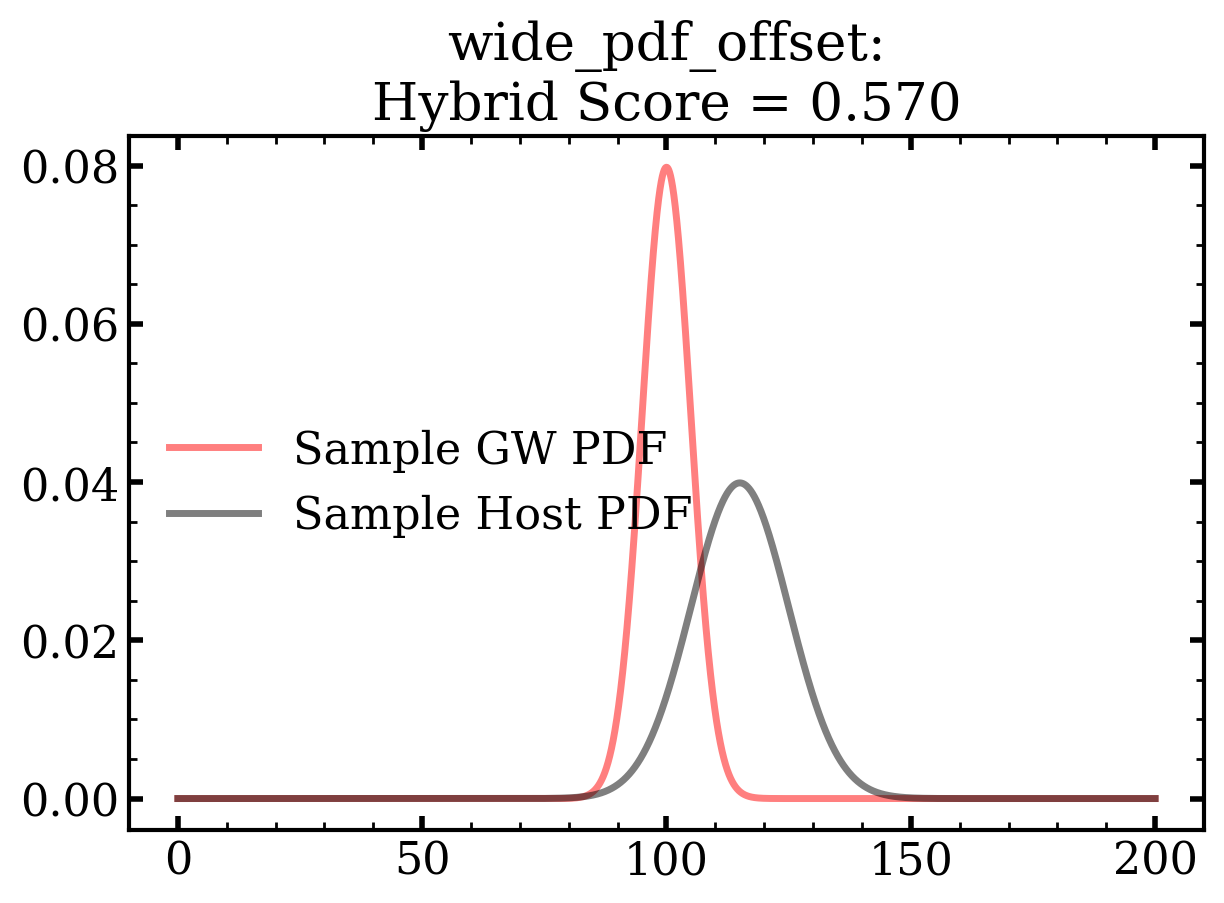

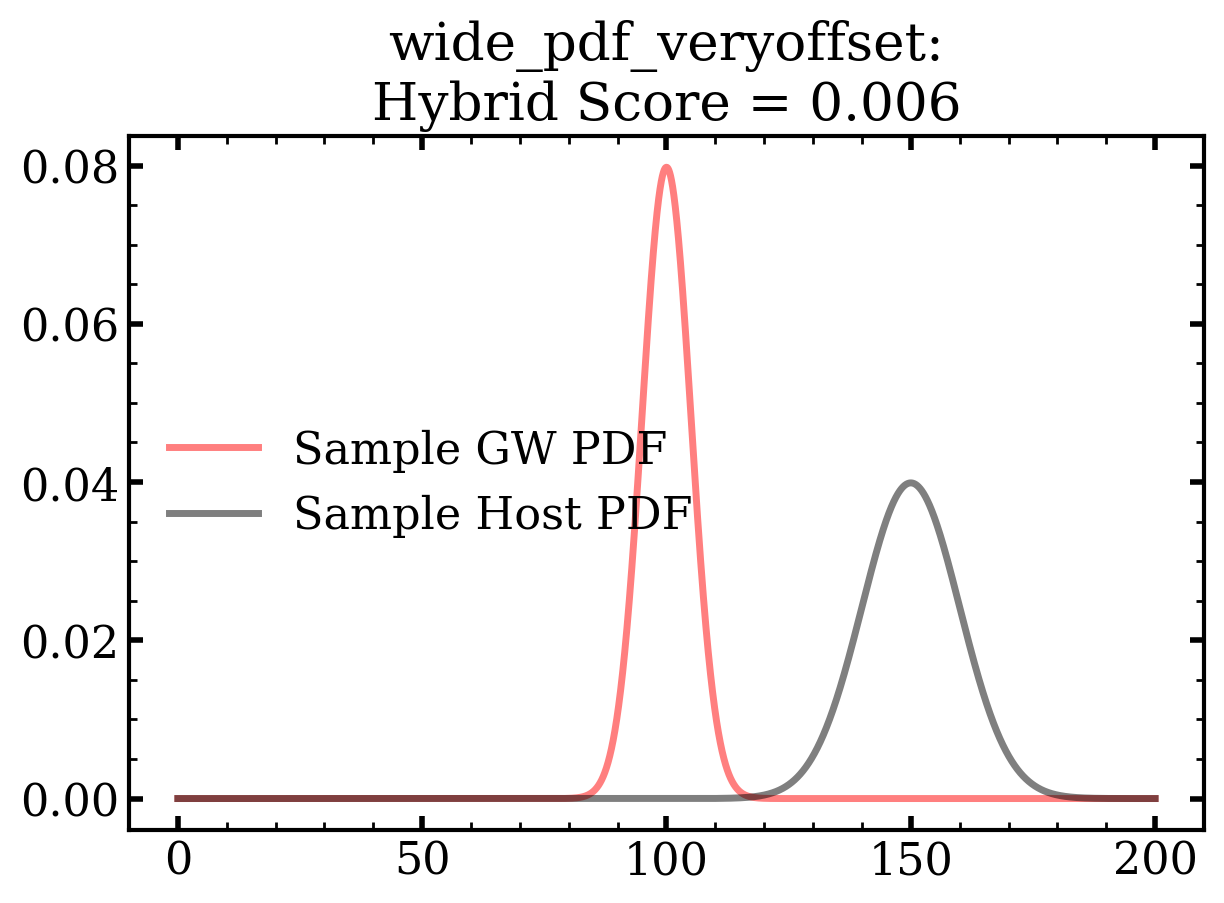

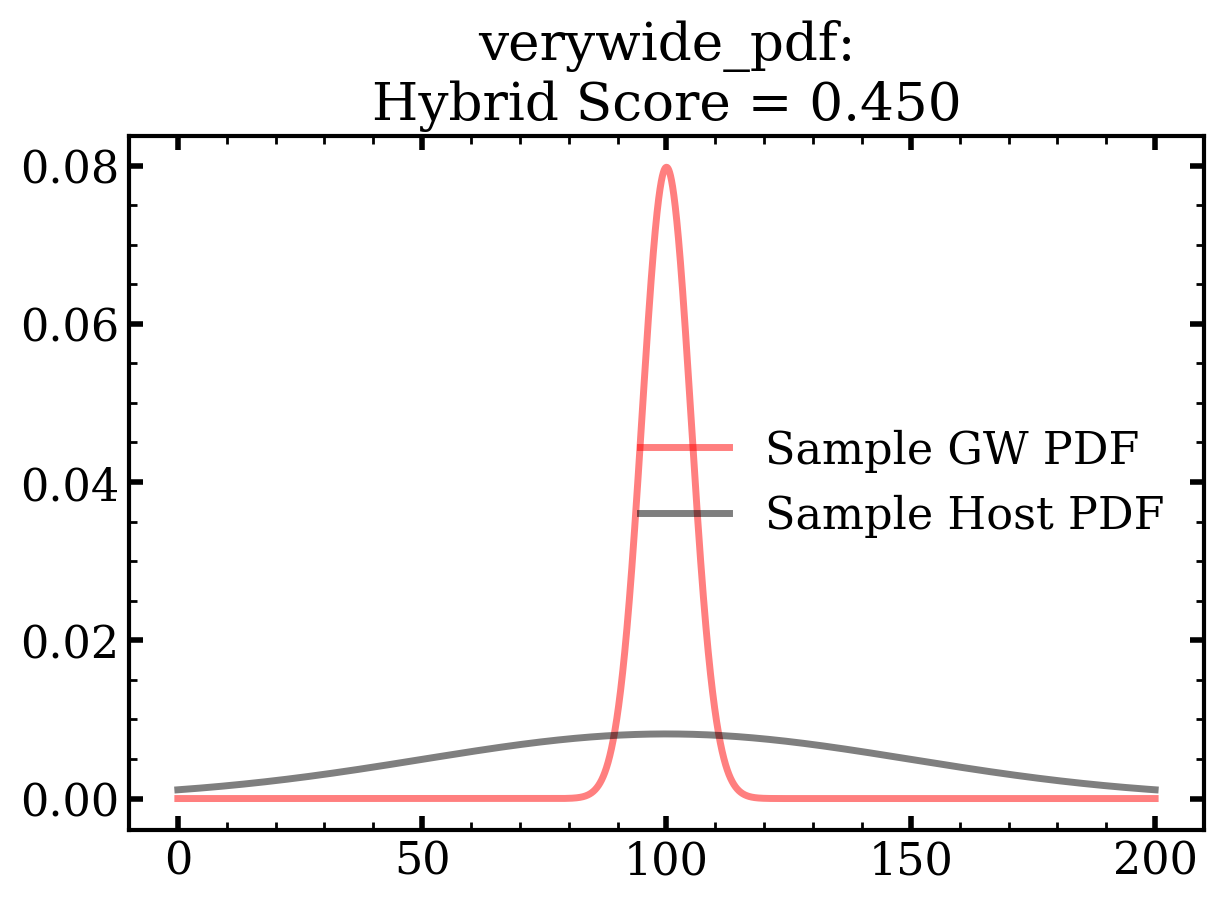

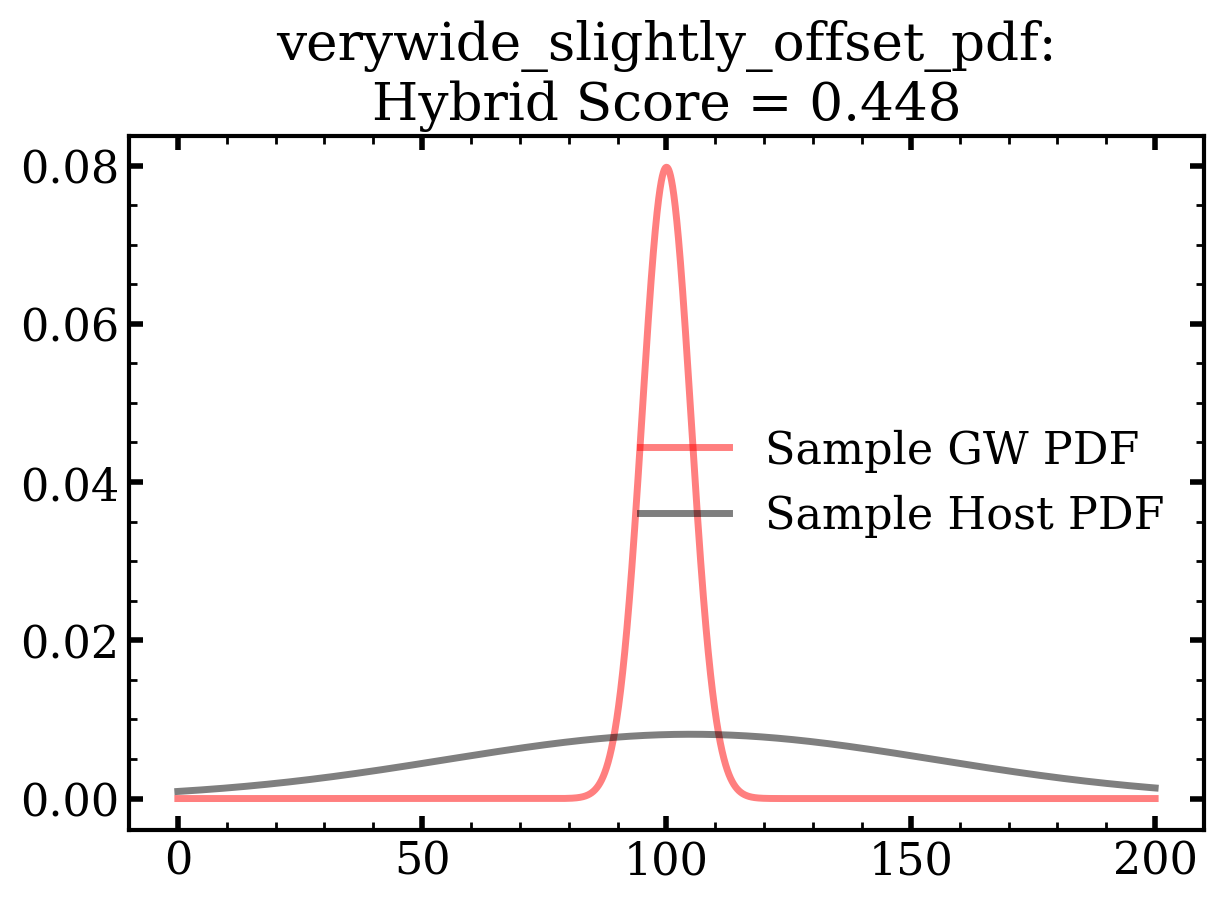

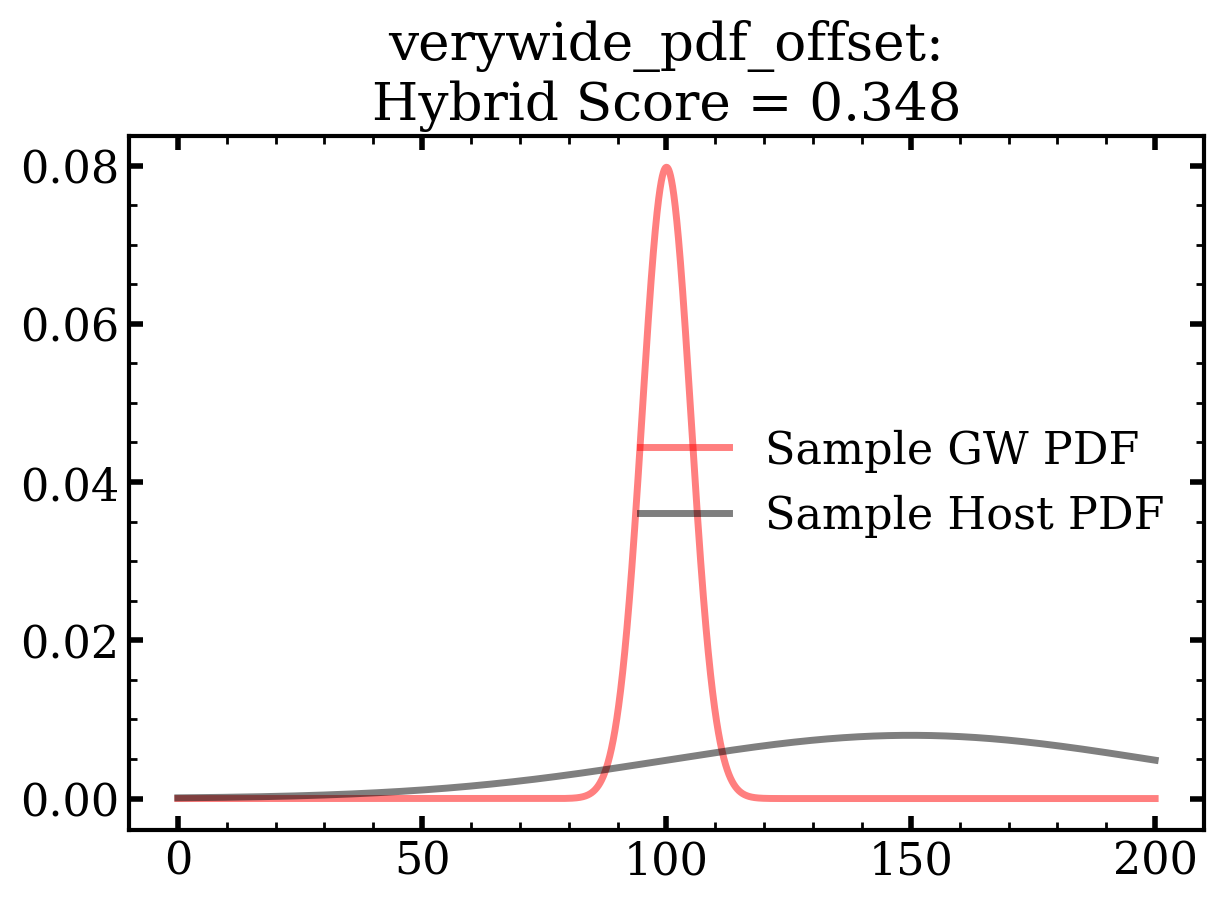

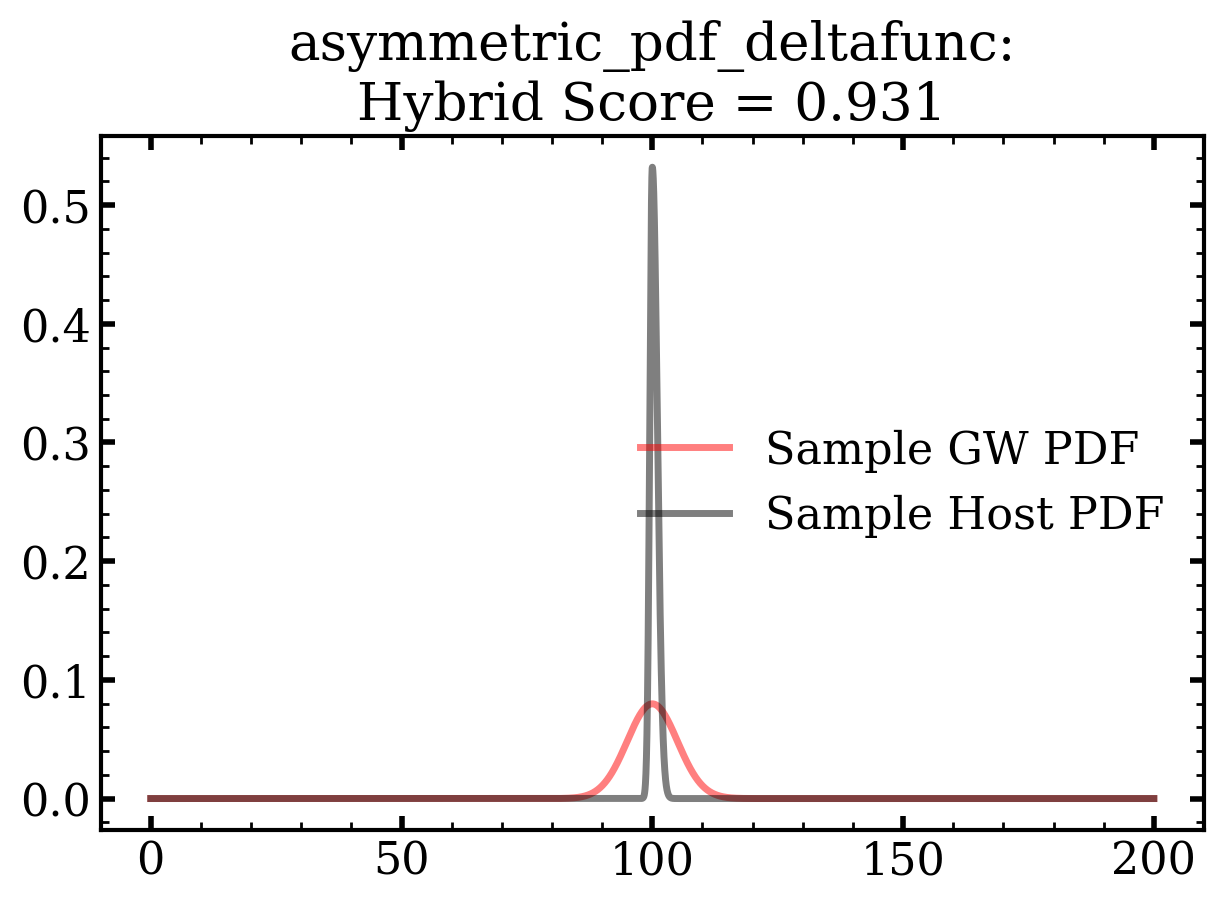

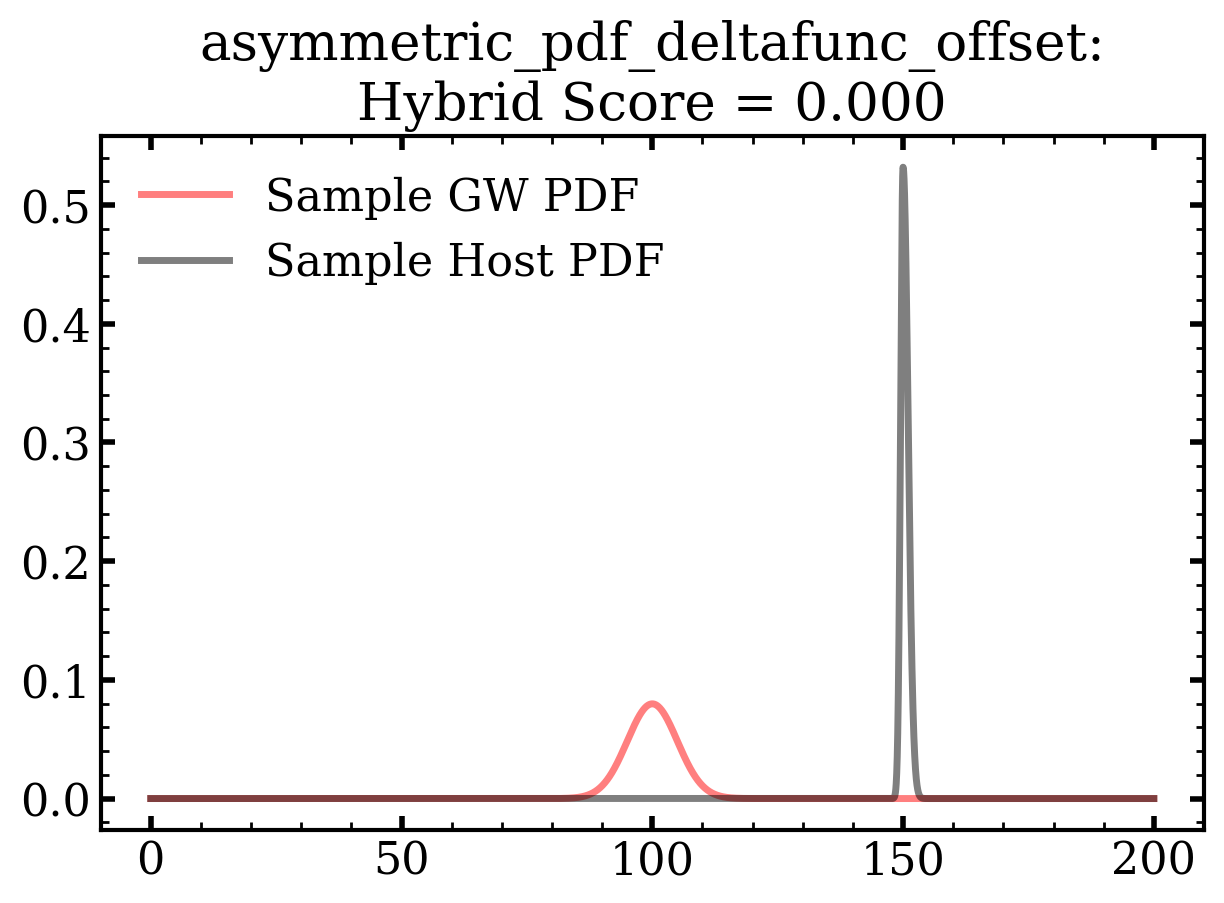

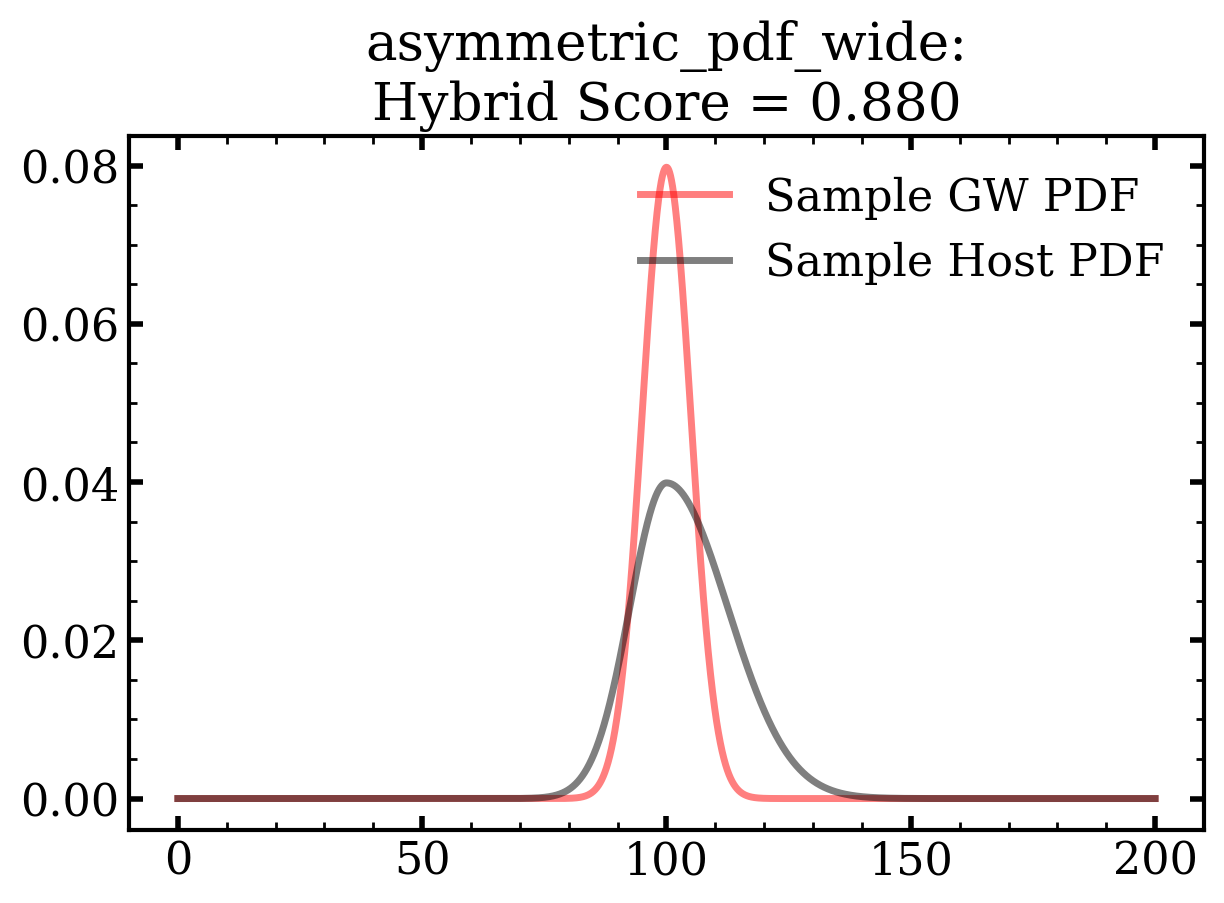

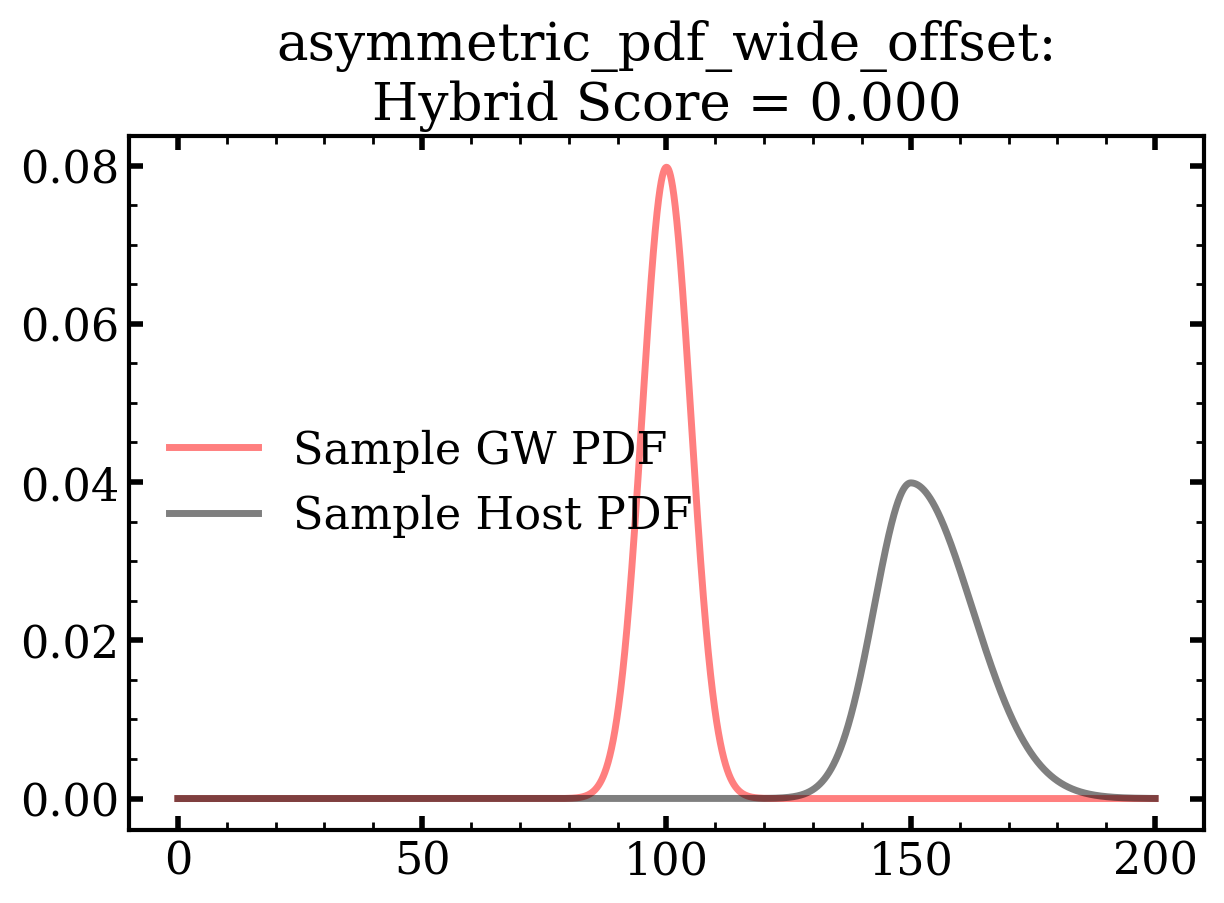

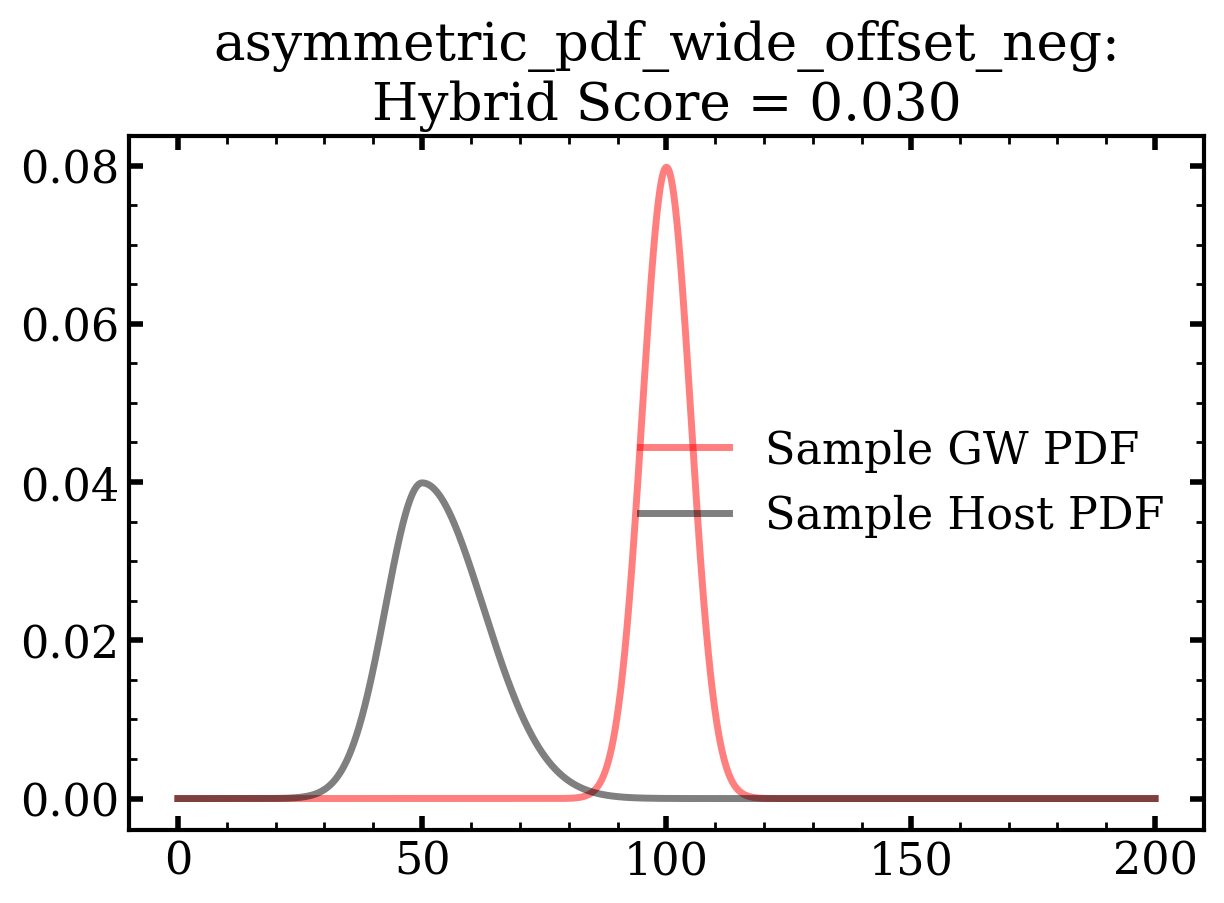

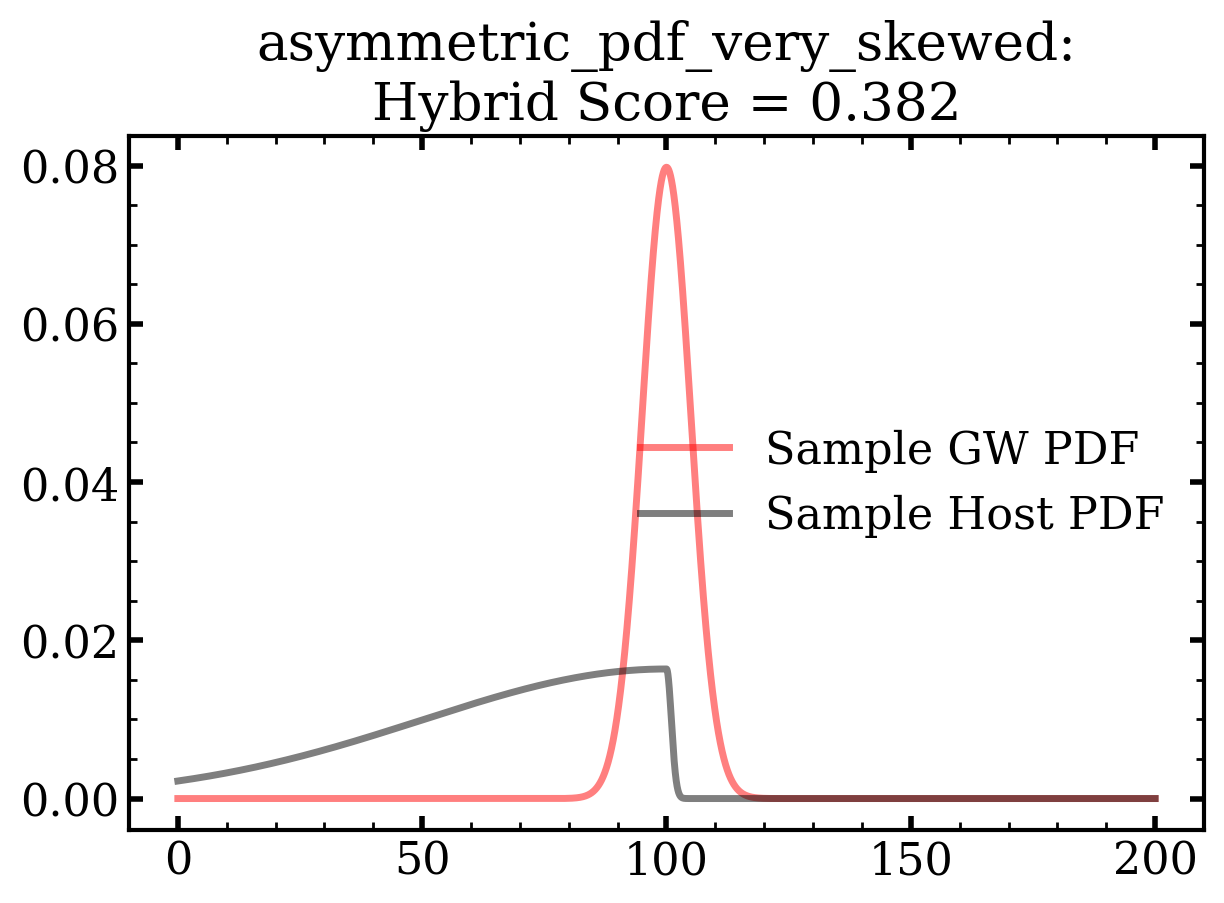

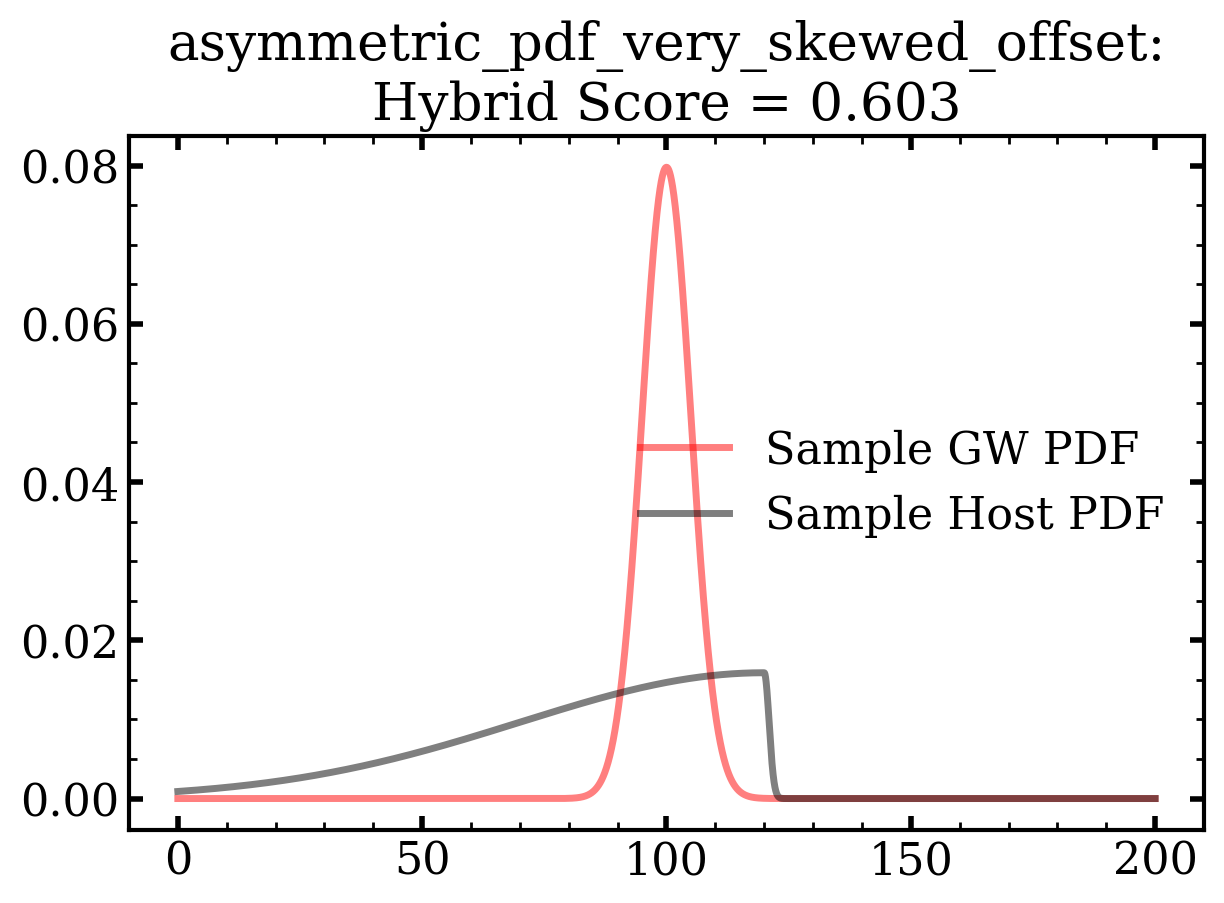

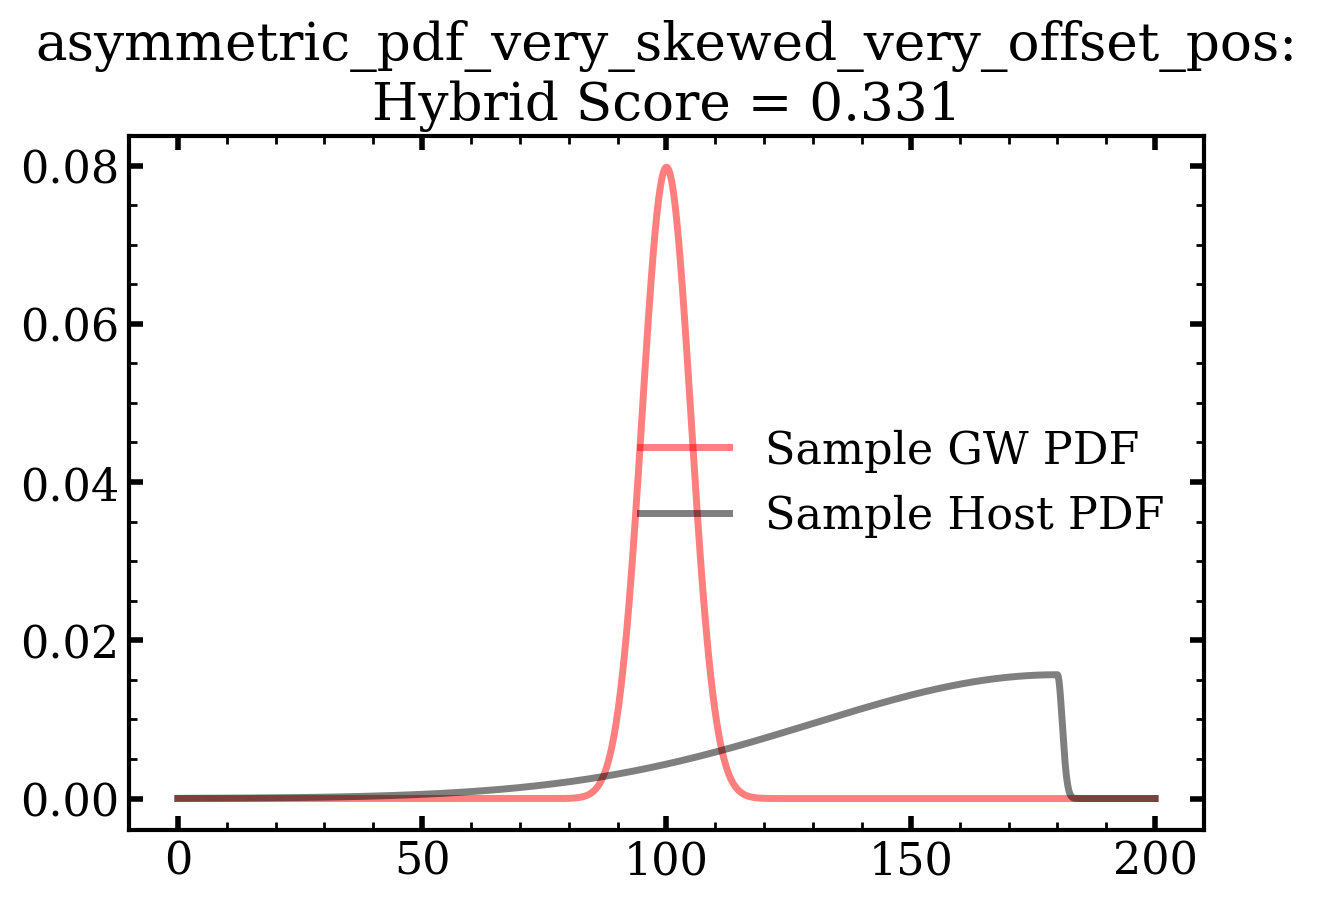

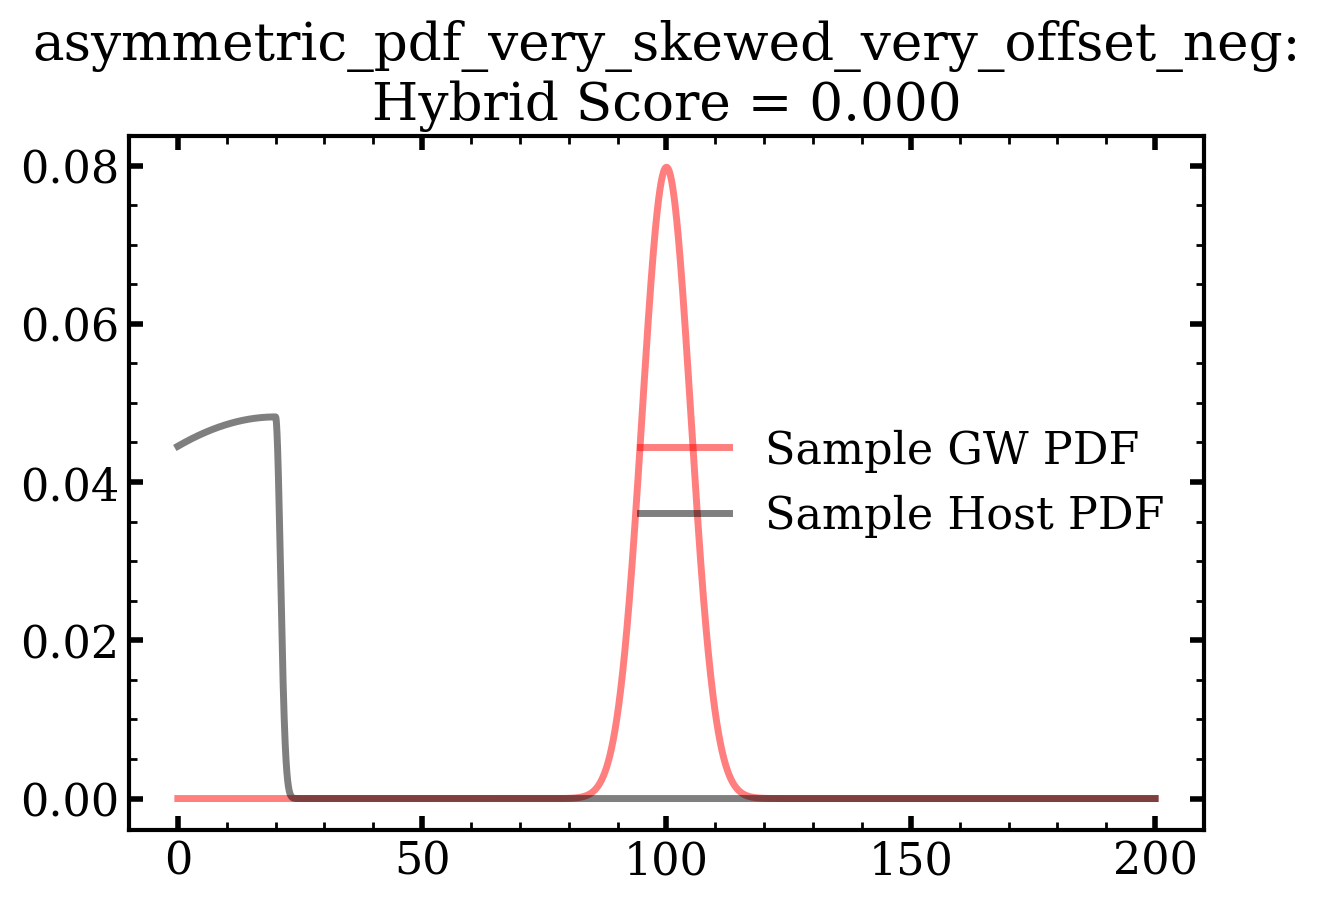

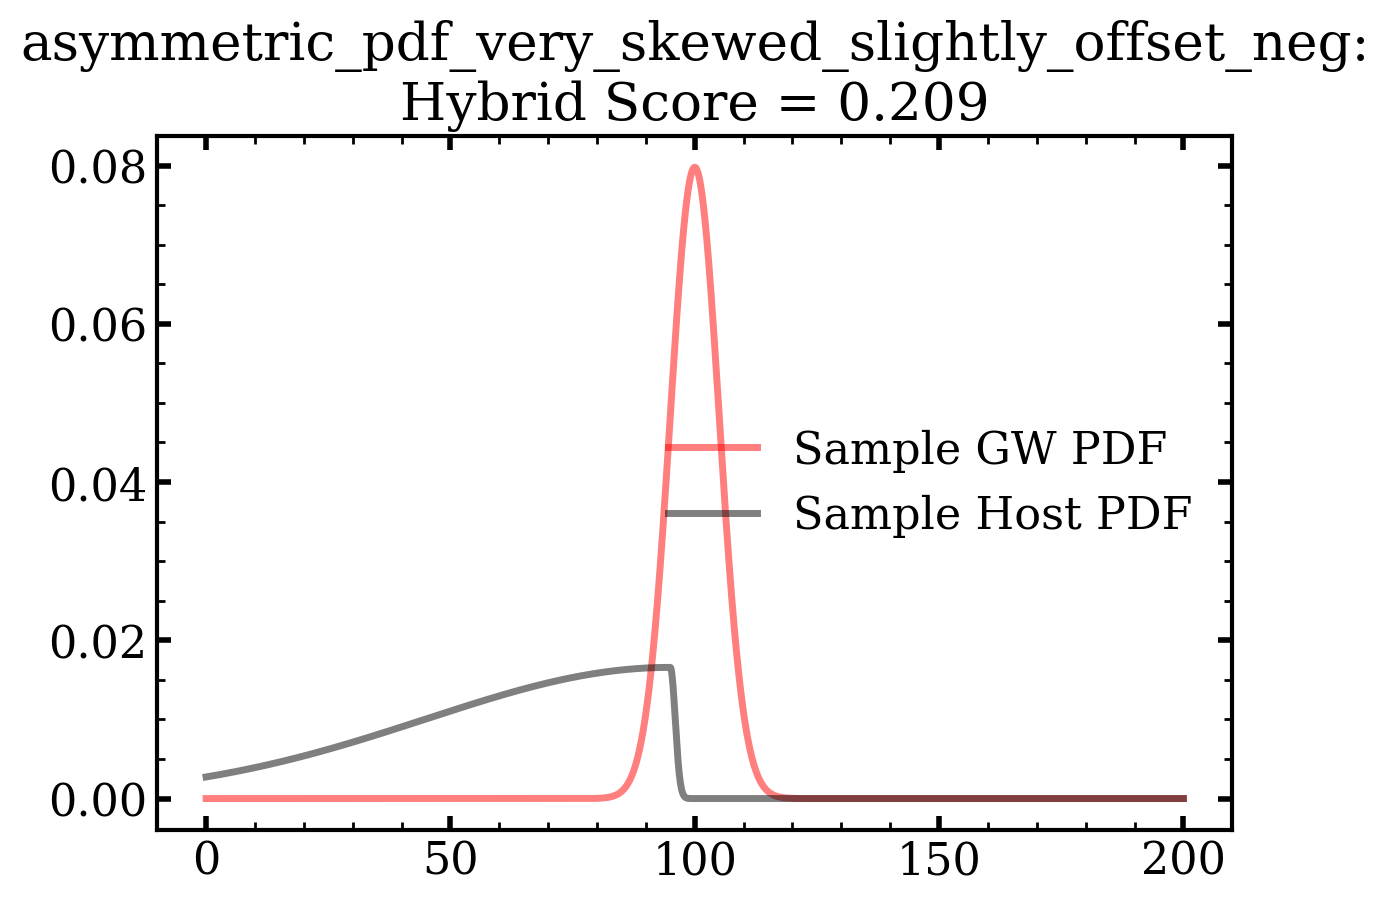

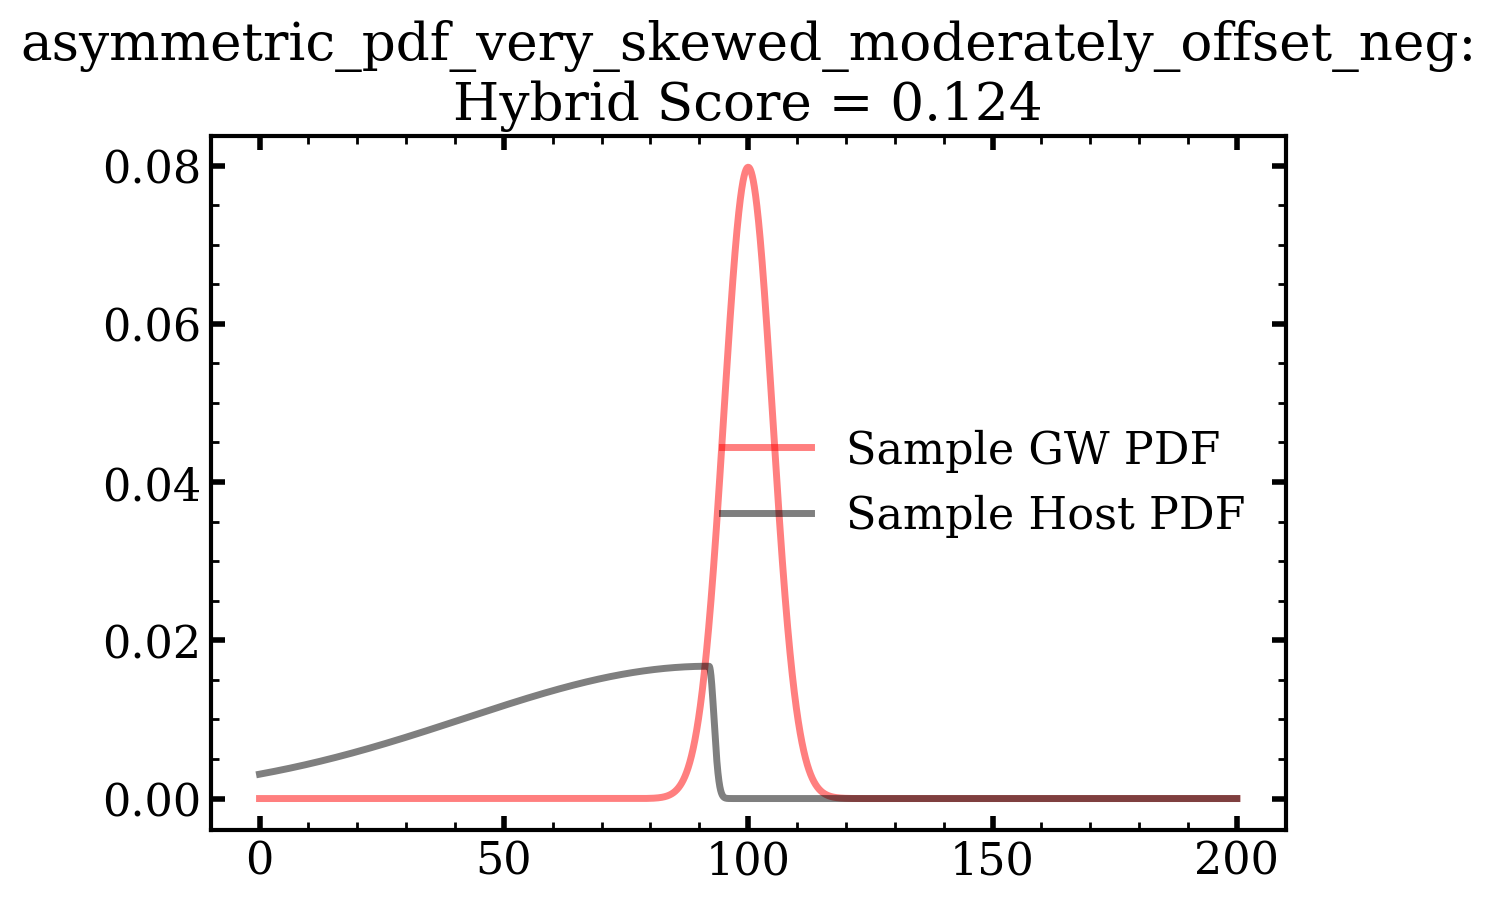

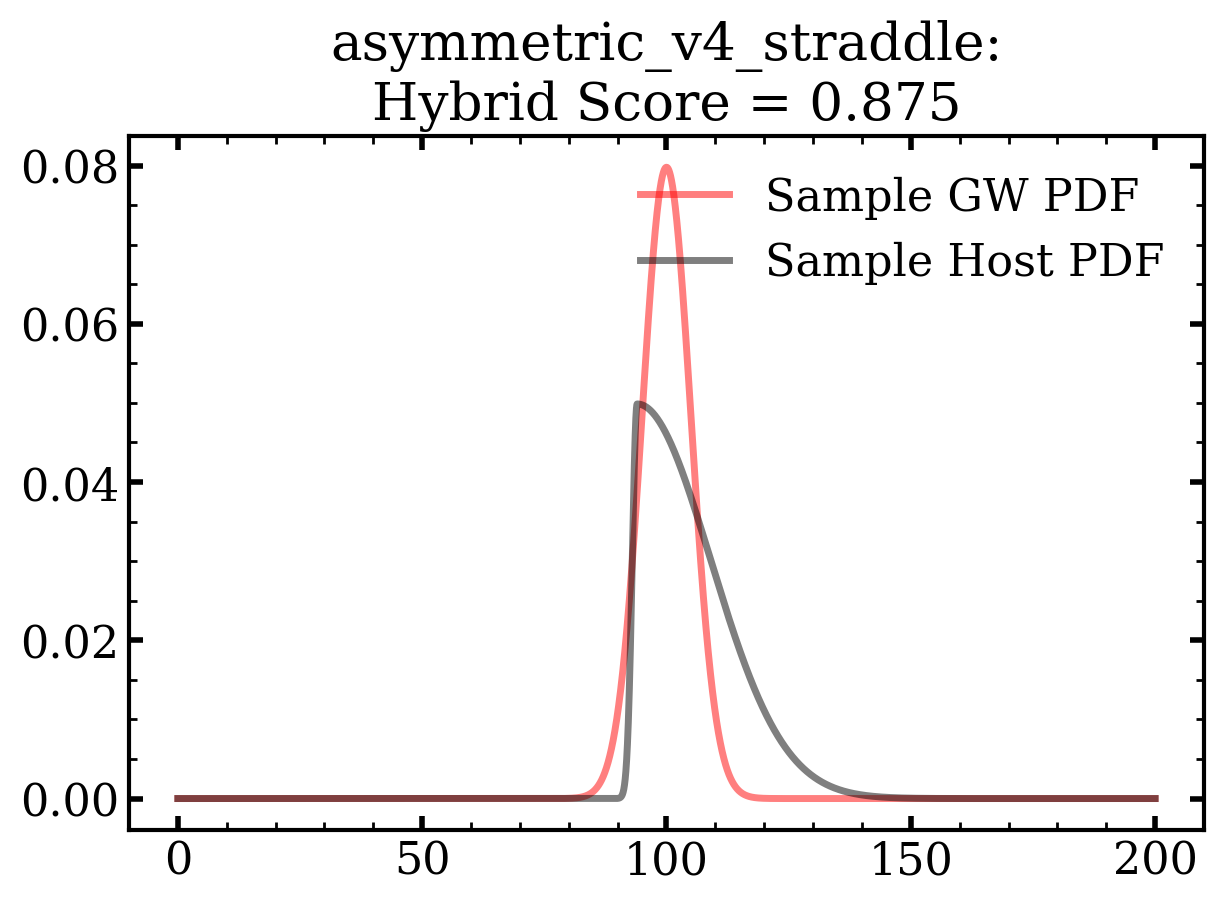

In [10]:
for label, test in test_pdfs.items():
    test_pdf = ag.pdf(PDF_X, **test)
    # norm_bc = bc_norm_median_asymmetric(0, test["loc"], 5, test["unc_minus"], test["unc_plus"])
    # mwu_res = mwu(0, test["loc"], 5, test["unc_minus"], test["unc_plus"])
    # z = zscore(0, test["loc"], 5)
    # z_resampled = resampled_zscore(0, test["loc"], 5, test["unc_minus"], test["unc_plus"])
    # njp = norm_joint_prob(0, test["loc"], 5, test["unc_minus"], test["unc_plus"])
    # cp = consistency_probability(0, test["loc"], 5, test["unc_minus"], test["unc_plus"])
    # old_bc = bc(base_pdf, test_pdf)
    h = hybrid(100, test["mean"], 5, test["unc_minus"], test["unc_plus"])
    
    # print(label, old_bc, norm_bc, mwu_res,z, z_resampled, njp, cp)
    print(label, h)
    

    fig, ax = plt.subplots()
    ax.plot(PDF_X, base_pdf, color="r", label="Sample GW PDF", alpha=0.5)
    ax.plot(PDF_X, test_pdf, color="k", label="Sample Host PDF", alpha=0.5)
    ax.legend()
    #ax.set_title(f"{label}:\nnorm_score={norm_bc:.3f}\nold_score={old_bc:.3f}\nzscore={z:.3f}\nresampled_zscore={z_resampled:.3f}\nNJP={njp:.3f}\ncp={cp:.3f}")
    ax.set_title(f"{label}:\nHybrid Score = {h:.3f}")
    fig.savefig(label+".png")